<a href="https://colab.research.google.com/github/Tejaswini-2207/Codsoft/blob/main/ML_Case_Study_2_Threats_of_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

print("ML Case Study 2 - Threats of AI")
print("Libraries imported successfully!")

ML Case Study 2 - Threats of AI
Libraries imported successfully!


In [2]:
import numpy as np
import pandas as pd

np.random.seed(42)

n = 500

gender = np.random.choice(["Male", "Female"], n)

experience = np.random.randint(1, 11, n)
skills = np.random.randint(40, 101, n)
education = np.random.randint(1, 6, n)

# Simulate historical gender bias
selected = (
    (experience >= 4) &
    (skills >= 60) &
    (education >= 3) &
    (gender == "Male")
).astype(int)

df = pd.DataFrame({
    "Gender": gender,
    "Experience": experience,
    "Skills": skills,
    "Education": education,
    "Selected": selected
})

print(df.head(10))
print("\nDataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())

   Gender  Experience  Skills  Education  Selected
0    Male           5      64          4         1
1  Female           7      43          4         0
2    Male           1      49          5         0
3    Male           3      42          5         0
4    Male           2      80          1         0
5  Female           9      84          2         0
6    Male          10      57          5         0
7    Male           6      86          4         1
8    Male          10      75          3         1
9  Female           3      86          4         0

Dataset Shape: (500, 5)

Missing Values:
 Gender        0
Experience    0
Skills        0
Education     0
Selected      0
dtype: int64


Selected
0    437
1     63
Name: count, dtype: int64

Selection Rate by Gender:
Gender
Female    0.000000
Male      0.258197
Name: Selected, dtype: float64


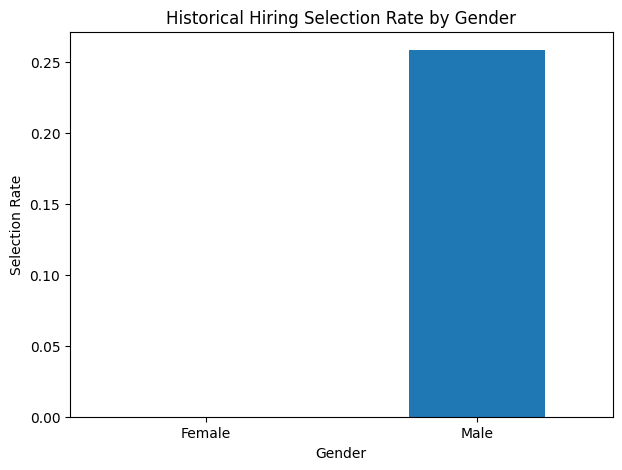

In [3]:
# Count selected and rejected candidates
print(df["Selected"].value_counts())

# Selection rate by gender
gender_analysis = df.groupby("Gender")["Selected"].mean()

print("\nSelection Rate by Gender:")
print(gender_analysis)

# Visualize selection rates
gender_analysis.plot(
    kind="bar",
    figsize=(7, 5),
    title="Historical Hiring Selection Rate by Gender"
)

plt.ylabel("Selection Rate")
plt.xlabel("Gender")
plt.xticks(rotation=0)
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# Convert gender into numerical values
df["Gender"] = df["Gender"].map({
    "Male": 1,
    "Female": 0
})

# Separate input features and target
X = df[["Gender", "Experience", "Skills", "Education"]]
y = df["Selected"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Train Decision Tree
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# Predictions
predictions = model.predict(X_test)

# Evaluation
print("Model Accuracy:", accuracy_score(y_test, predictions))
print("\nClassification Report:\n")
print(classification_report(y_test, predictions, zero_division=0))

Model Accuracy: 1.0

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        86
           1       1.00      1.00      1.00        14

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



Predicted Selection Rates:
Female: 0.0
Male: 0.2641509433962264

Demographic Parity Difference: 0.2641509433962264


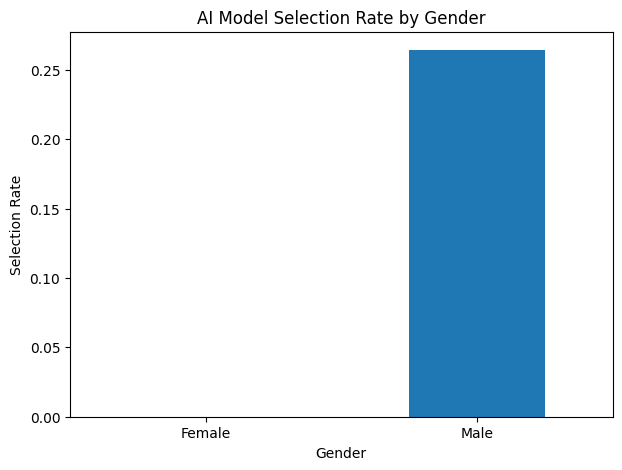

In [5]:
# Create results dataframe
results = X_test.copy()

results["Actual"] = y_test
results["Predicted"] = predictions

# Calculate predicted selection rates
selection_rates = results.groupby("Gender")["Predicted"].mean()

print("Predicted Selection Rates:")
print("Female:", selection_rates[0])
print("Male:", selection_rates[1])

# Calculate demographic parity difference
dp_difference = abs(selection_rates[1] - selection_rates[0])

print("\nDemographic Parity Difference:", dp_difference)

# Visualize results
selection_rates.index = ["Female", "Male"]

selection_rates.plot(
    kind="bar",
    figsize=(7, 5),
    title="AI Model Selection Rate by Gender"
)

plt.ylabel("Selection Rate")
plt.xlabel("Gender")
plt.xticks(rotation=0)
plt.show()

In [6]:
# Remove Gender from input features
X_fair = df[["Experience", "Skills", "Education"]]
y_fair = df["Selected"]

# Split dataset
X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_fair,
    y_fair,
    test_size=0.2,
    random_state=42
)

# Train new model
fair_model = DecisionTreeClassifier(random_state=42)
fair_model.fit(X_train_f, y_train_f)

# Predict
fair_predictions = fair_model.predict(X_test_f)

print("Accuracy after removing Gender:",
      accuracy_score(y_test_f, fair_predictions))

Accuracy after removing Gender: 0.88


FAIRNESS COMPARISON
        Original Model  Model Without Gender
Female        0.000000              0.085106
Male          0.264151              0.150943

Original DPD: 0.2641509433962264
Mitigated DPD: 0.06583701324769169


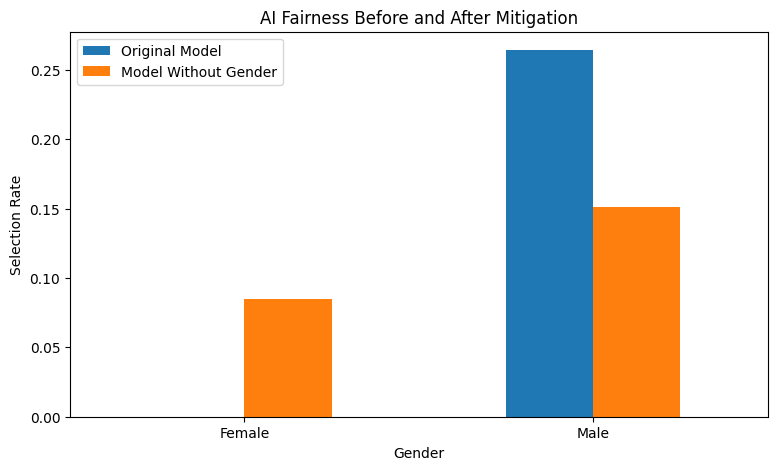

In [7]:
# Original model results
original_results = pd.DataFrame({
    "Gender": X_test["Gender"].values,
    "Prediction": predictions
})

# Model without Gender results
fair_results = pd.DataFrame({
    "Gender": X_test["Gender"].values,
    "Prediction": fair_predictions
})

# Calculate selection rates
original_rates = original_results.groupby("Gender")["Prediction"].mean()

fair_rates = fair_results.groupby("Gender")["Prediction"].mean()

# Comparison table
comparison = pd.DataFrame({
    "Original Model": original_rates,
    "Model Without Gender": fair_rates
})

comparison.index = ["Female", "Male"]

print("FAIRNESS COMPARISON")
print(comparison)

# Calculate demographic parity difference
original_dpd = abs(original_rates[1] - original_rates[0])
fair_dpd = abs(fair_rates[1] - fair_rates[0])

print("\nOriginal DPD:", original_dpd)
print("Mitigated DPD:", fair_dpd)

# Visualize
comparison.plot(kind="bar", figsize=(9, 5))

plt.title("AI Fairness Before and After Mitigation")
plt.ylabel("Selection Rate")
plt.xlabel("Gender")
plt.xticks(rotation=0)
plt.legend()
plt.show()